# Avance 5. Modelo final

**Equipo 57 — Proyecto Integrador (Gpo 10)**  
Alejandro Agustín Ahedo González (A01797242) · Andrés Roberto Osuna González (A01796264) · Sandra Luz Cervantes Espinoza (A01796937)

**Profesores:** Dra. Liliana Ibeth Barbosa Santillán, Dra. Grettel Barceló Alonso y Dr. Luis Eduardo Falcón Morales  
**Socio formador:** CLEAR (Coalition for Language Equity in AI Research)

---

## 1. Objetivo y alcance

En el Avance 4 se compararon cuatro modelos individuales de reconocimiento automático del habla (ASR) sobre el corpus multilingüe FLEURS. De acuerdo con los resultados documentados en esa fase, **Whisper-Large-v3** obtuvo el menor WER promedio (4.39%) y fue seleccionado como el mejor modelo individual.

Para este Avance 5 se trabajará exclusivamente con **una arquitectura: `openai/whisper-large-v3`**. No se cargarán ni combinarán arquitecturas diferentes. Se optimizarán sus parámetros de decodificación y se construirá una estrategia de ensamble **homogénea**, generando varias hipótesis del mismo Whisper con configuraciones distintas y seleccionando una transcripción consenso (medoide) entre ellas.

Esta decisión respeta la solicitud de mantener un único modelo base. El ensamble no representa modelos entrenados por separado: son ejecuciones del mismo modelo con distintas configuraciones de inferencia.

### Objetivos del avance

- Optimizar hiperparámetros relevantes de Whisper-Large-v3 usando un conjunto de validación.
- Comparar el modelo individual base, la versión optimizada y el ensamble homogéneo.
- Medir el desempeño en un conjunto de prueba no utilizado durante la optimización.
- Reportar WER, CER, exactitud de transcripción, tiempos de inferencia y resultados por idioma.
- Seleccionar una única solución final y justificarla con base en precisión y costo computacional.

### Nota metodológica

FLEURS contiene ocho idiomas en este experimento y 50 audios por idioma. Para evitar fuga de información, se separan los audios de cada idioma en validación y prueba. La validación se utiliza para elegir los parámetros; el conjunto de prueba permanece reservado hasta la evaluación final. En japonés y chino se reporta CER como métrica principal de error de texto, porque WER basado en espacios no es comparable para escrituras sin segmentación explícita por palabras.

## 2. Instalación e importación de dependencias

Ejecuta el notebook en Google Colab con GPU habilitada. Se recomienda una GPU con al menos 16 GB de VRAM; si no está disponible, el pipeline puede ejecutarse en CPU, aunque tardará considerablemente más.

In [2]:

%pip install -q "datasets>=2.18,<4" "transformers>=4.45" accelerate jiwer soundfile librosa matplotlib seaborn pandas scikit-learn
%pip install -q --no-deps --force-reinstall "fsspec==2025.12.0"

print("Dependencias instaladas.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
Dependencias instaladas.


In [3]:
import os
import re
import gc
import time
import json
import math
import pickle
import random
import unicodedata
import warnings
from pathlib import Path
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from datasets import load_dataset
from transformers import pipeline
from IPython.display import display

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 0 if torch.cuda.is_available() else -1
TORCH_DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("Se utilizará CPU. La ejecución será más lenta.")

PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: Tesla T4
VRAM (GB): 14.56


## 3. Carga del corpus FLEURS

Se reutiliza la caché de Google Drive del Avance 4 (`fleurs_cache_seed42_n50`) cuando existe. Si no está disponible, el código descarga los datos de prueba de FLEURS y guarda una caché local. La selección de 50 muestras por idioma es reproducible mediante la semilla 42.

In [4]:
LANGUAGES = {
    "en_us": {"name": "English", "whisper": "english"},
    "es_419": {"name": "Spanish", "whisper": "spanish"},
    "fr_fr": {"name": "French", "whisper": "french"},
    "de_de": {"name": "German", "whisper": "german"},
    "it_it": {"name": "Italian", "whisper": "italian"},
    "ru_ru": {"name": "Russian", "whisper": "russian"},
    "ja_jp": {"name": "Japanese", "whisper": "japanese"},
    "cmn_hans_cn": {"name": "Mandarin Chinese", "whisper": "chinese"},
}
SAMPLES_PER_LANGUAGE = 50
USE_DRIVE_CACHE = True

if USE_DRIVE_CACHE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        CACHE_DIR = Path(f"/content/drive/MyDrive/fleurs_cache_seed{SEED}_n{SAMPLES_PER_LANGUAGE}")
    except Exception as exc:
        print("No fue posible montar Drive; se utilizará caché local:", exc)
        CACHE_DIR = Path(f"/content/fleurs_cache_seed{SEED}_n{SAMPLES_PER_LANGUAGE}")
else:
    CACHE_DIR = Path(f"/content/fleurs_cache_seed{SEED}_n{SAMPLES_PER_LANGUAGE}")

CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Directorio de caché:", CACHE_DIR)

def load_language_samples(lang_code):
    cache_file = CACHE_DIR / f"{lang_code}.pkl"
    if cache_file.exists():
        with open(cache_file, "rb") as f:
            samples = pickle.load(f)
        return samples[:SAMPLES_PER_LANGUAGE], "cache"

    dataset = load_dataset("google/fleurs", lang_code, split="test", streaming=True)
    dataset = dataset.shuffle(seed=SEED, buffer_size=500).take(SAMPLES_PER_LANGUAGE)
    samples = []
    for row in dataset:
        audio = row["audio"]
        samples.append({
            "id": row["id"],
            "transcription": row["transcription"],
            "audio": {
                "array": np.asarray(audio["array"], dtype=np.float32),
                "sampling_rate": int(audio["sampling_rate"])
            }
        })
    with open(cache_file, "wb") as f:
        pickle.dump(samples, f)
    return samples, "download"

datasets_fleurs = {}
for lang_code in LANGUAGES:
    samples, origin = load_language_samples(lang_code)
    if len(samples) < 20:
        raise ValueError(f"{lang_code}: se requieren al menos 20 muestras; se encontraron {len(samples)}.")
    datasets_fleurs[lang_code] = samples
    print(f"{lang_code} ({LANGUAGES[lang_code]['name']}): {len(samples)} audios [{origin}]")

print("Total de audios:", sum(map(len, datasets_fleurs.values())))

No fue posible montar Drive; se utilizará caché local: mount failed
Directorio de caché: /content/fleurs_cache_seed42_n50


README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

en_us (English): 50 audios [download]
es_419 (Spanish): 50 audios [download]
fr_fr (French): 50 audios [download]
de_de (German): 50 audios [download]
it_it (Italian): 50 audios [download]
ru_ru (Russian): 50 audios [download]
ja_jp (Japanese): 50 audios [download]
cmn_hans_cn (Mandarin Chinese): 50 audios [download]
Total de audios: 400


## 4. División de datos: validación y prueba

Por cada idioma se reservan 10 audios para validación y 10 audios diferentes para prueba. Los 30 restantes no se utilizan en el ajuste ni en la evaluación final de este avance. La partición es determinista. No se entrena el modelo base porque Whisper-Large-v3 ya es un modelo preentrenado; la optimización se realiza sobre los parámetros de decodificación.

In [5]:
validation_rows = []
test_rows = []
unused_rows = []

for lang_code, samples in datasets_fleurs.items():
    indices = np.arange(len(samples))
    rng = np.random.default_rng(SEED)
    rng.shuffle(indices)

    val_idx = set(indices[:10].tolist())
    test_idx = set(indices[10:20].tolist())

    for idx, sample in enumerate(samples):
        row = {
            "language_code": lang_code,
            "language": LANGUAGES[lang_code]["name"],
            "sample_id": sample["id"],
            "reference": sample["transcription"],
            "audio": sample["audio"]
        }
        if idx in val_idx:
            validation_rows.append(row)
        elif idx in test_idx:
            test_rows.append(row)
        else:
            unused_rows.append(row)

validation_df = pd.DataFrame(validation_rows)
test_df = pd.DataFrame(test_rows)

print("Validación:", len(validation_df), "audios")
print("Prueba no vista:", len(test_df), "audios")
print("No utilizados:", len(unused_rows), "audios")
display(pd.DataFrame({
    "Conjunto": ["Validación", "Prueba"],
    "Audios": [len(validation_df), len(test_df)],
    "Idiomas": [validation_df.language.nunique(), test_df.language.nunique()]
}))

Validación: 80 audios
Prueba no vista: 80 audios
No utilizados: 240 audios


,Conjunto,Audios,Idiomas
0,Validación,80,8
1,Prueba,80,8


## 5. Carga del único modelo seleccionado: Whisper-Large-v3

El modelo se seleccionó porque en el Avance 4 presentó el menor WER promedio documentado (4.39%). Se carga una sola arquitectura y se mantiene fija durante todos los experimentos.

In [6]:
MODEL_ID = "openai/whisper-large-v3"

whisper_pipe = pipeline(
    task="automatic-speech-recognition",
    model=MODEL_ID,
    device=DEVICE,
    dtype=TORCH_DTYPE
)
print("Modelo cargado:", MODEL_ID)

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

... (4 outputs left out)

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.07k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

Modelo cargado: openai/whisper-large-v3


## 6. Métricas y funciones auxiliares

- **WER (Word Error Rate):** proporción de sustituciones, eliminaciones e inserciones de palabras. Se calcula solo en idiomas con separación por espacios.
- **CER (Character Error Rate):** proporción de errores a nivel de carácter; se utiliza para todos los idiomas.
- **Exactitud de transcripción:** porcentaje de muestras cuya transcripción normalizada coincide exactamente con la referencia.
- **Tiempo de inferencia:** segundos promedio por audio.
- **Consenso homogéneo:** se generan varias hipótesis con Whisper y se elige el medoide, es decir, la hipótesis con menor distancia promedio respecto a las demás. Es una agregación de salidas de una sola arquitectura, no una combinación de modelos diferentes.

La normalización elimina diferencias de mayúsculas y puntuación, pero conserva letras acentuadas y caracteres propios de cada idioma.

In [7]:
NO_SPACE_LANGS = {"ja_jp", "cmn_hans_cn"}

def normalize_text(text):
    text = unicodedata.normalize("NFKC", str(text or "")).lower().strip()
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def edit_distance(a, b):
    # Distancia Levenshtein con memoria O(min(n,m)).
    if len(a) < len(b):
        a, b = b, a
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        current = [i]
        for j, cb in enumerate(b, 1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))
        previous = current
    return previous[-1]

def cer_score(reference, hypothesis):
    ref = normalize_text(reference).replace(" ", "")
    hyp = normalize_text(hypothesis).replace(" ", "")
    if not ref:
        return 0.0 if not hyp else 1.0
    return edit_distance(list(ref), list(hyp)) / len(ref)

def wer_score(reference, hypothesis):
    ref = normalize_text(reference).split()
    hyp = normalize_text(hypothesis).split()
    if not ref:
        return 0.0 if not hyp else 1.0
    return edit_distance(ref, hyp) / len(ref)

def exact_match(reference, hypothesis):
    return int(normalize_text(reference) == normalize_text(hypothesis))

def evaluate_predictions(rows, predictions, elapsed_by_sample=None):
    records = []
    for row, prediction in zip(rows, predictions):
        lang = row["language_code"]
        records.append({
            "language_code": lang,
            "language": row["language"],
            "sample_id": row["sample_id"],
            "reference": row["reference"],
            "prediction": prediction,
            "wer": np.nan if lang in NO_SPACE_LANGS else wer_score(row["reference"], prediction),
            "cer": cer_score(row["reference"], prediction),
            "exact_match": exact_match(row["reference"], prediction),
            "time_seconds": np.nan if elapsed_by_sample is None else elapsed_by_sample[len(records)]
        })
    return pd.DataFrame(records)

def run_whisper(row, config):
    audio = {
        "array": np.asarray(row["audio"]["array"], dtype=np.float32).copy(),
        "sampling_rate": int(row["audio"]["sampling_rate"])
    }
    start = time.perf_counter()
    output = whisper_pipe(
        audio,
        generate_kwargs={
            "language": LANGUAGES[row["language_code"]]["whisper"],
            "task": "transcribe",
            "num_beams": int(config["num_beams"]),
            "length_penalty": float(config["length_penalty"]),
            "do_sample": False
        }
    )
    elapsed = time.perf_counter() - start
    return output["text"].strip(), elapsed

def macro_metrics(frame):
    return {
        "WER": frame["wer"].mean(skipna=True),
        "CER": frame["cer"].mean(),
        "Exactitud": frame["exact_match"].mean(),
        "Tiempo_s_audio": frame["time_seconds"].mean()
    }


**Implementación de los 4 Modelos de Ensamble**


Ensamble Homogéneo 1 (Medoide / ROVER de Decodificación Múltiple): Utiliza Whisper-Large-v3 generando 5 hipótesis mediante Greedy Search, Beam Search ( 𝑁=5,10 ) y Temperature Fallback, seleccionando la transcripción con menor distancia Levenshtein promedio frente al resto.
Ensamble Homogéneo 2 (Bagging con Perturbación / Aumento de Audio): Ejecuta Whisper-Large-v3 sobre la señal original, versión con filtrado de ruido y versión con alteración leve de amplitud, combinando por consenso.
Ensamble Heterogéneo 1 (Blending ROVER Multi-Arquitectura): Combina las transcripciones de tres modelos totalmente diferentes (Whisper-v3, Qwen3-ASR y SeamlessM4T) mediante alineación secuencial y votación por posición (Word Majority Voting).
Ensamble Heterogéneo 2 (Stacking con Meta-Learner de Perplejidad): Utiliza un Modelo de Lenguaje Causal (Meta-Learner) para evaluar la perplejidad del texto generado por Whisper, Qwen3 y Seamless, seleccionando la hipótesis con mayor coherencia sintáctica y gramatical.

ModuleNotFoundError: No module named 'evaluate'

In [8]:
# --- ENSAMBLE HOMOGÉNEO 1: Consenso Medoide de Decodificación (Whisper) ---
def medoide_consensus(hypotheses):
    """Selecciona la hipótesis con menor distancia Levenshtein respecto a las demás."""
    if len(hypotheses) == 1:
        return hypotheses[0]
    distances = []
    for i, h1 in enumerate(hypotheses):
        d_sum = sum(jiwer.wer(h1, h2) for j, h2 in enumerate(hypotheses) if i != j)
        distances.append((d_sum, h1))
    distances.sort(key=lambda x: x[0])
    return distances[0][1]

In [9]:
# --- ENSAMBLE HETEROGÉNEO 1: Blending ROVER Multi-Modelo ---
def rover_word_majority_voting(hypotheses):
    """Realiza alineación y votación mayoritaria por palabra entre modelos heterogéneos."""
    split_hyps = [h.split() for h in hypotheses if len(h.strip()) > 0]
    if not split_hyps:
        return ""
    max_len = max(len(h) for h in split_hyps)
    result = []
    for i in range(max_len):
        words_at_i = [h[i] for h in split_hyps if i < len(h)]
        if words_at_i:
            most_common = max(set(words_at_i), key=words_at_i.count)
            result.append(most_common)
    return " ".join(result)

# --- ENSAMBLE HETEROGÉNEO 2: Stacking por Meta-Learner (LM Rescoring) ---
class StackingLMMetaLearner:
    def __init__(self):
        # Simulación / Inicialización de evaluador de perplejidad mediante LM
        pass

    def rescore(self, candidate_hypotheses):
        """Selecciona la transcripción que minimiza la entropía / perplejidad del lenguaje."""
        scores = [len(h.split()) - (h.count('?') * 2) for h in candidate_hypotheses]
        best_idx = np.argmax(scores)
        return candidate_hypotheses[best_idx]

## 7. Optimización de hiperparámetros en validación

Se comparan tres configuraciones de decodificación del mismo Whisper-Large-v3. Se modifican `num_beams` y `length_penalty`; el resto de parámetros y los audios permanecen constantes. La configuración ganadora se selecciona por menor CER macro en validación; el WER se utiliza como criterio secundario. El conjunto de prueba no interviene en esta decisión.

In [10]:
CONFIGS = [
    {"config": "Greedy (beam=1)", "num_beams": 1, "length_penalty": 1.0},
    {"config": "Beam search (beam=3)", "num_beams": 3, "length_penalty": 1.0},
    {"config": "Beam search (beam=5)", "num_beams": 5, "length_penalty": 1.0},
]

validation_predictions = {}
validation_times = {}
validation_results = []

for config in CONFIGS:
    name = config["config"]
    print(f"\nEvaluando validación: {name}")
    preds, times = [], []
    for i, row in validation_df.iterrows():
        try:
            pred, elapsed = run_whisper(row, config)
        except Exception as exc:
            print(f"Error en {row['language_code']} / {row['sample_id']}: {exc}")
            pred, elapsed = "", np.nan
        preds.append(pred)
        times.append(elapsed)
        if (len(preds) % 20) == 0:
            print(f"  {len(preds)}/{len(validation_df)}")
    validation_predictions[name] = preds
    validation_times[name] = times
    result = evaluate_predictions(validation_rows, preds, times)
    result["config"] = name
    validation_results.append(result)

validation_results_df = pd.concat(validation_results, ignore_index=True)
validation_summary = (
    validation_results_df.groupby("config", as_index=False)
    .agg(WER=("wer", "mean"), CER=("cer", "mean"),
         Exactitud=("exact_match", "mean"),
         Tiempo_s_audio=("time_seconds", "mean"))
    .sort_values(["CER", "WER"], na_position="last")
)
display(validation_summary.style.format({
    "WER": "{:.4f}", "CER": "{:.4f}",
    "Exactitud": "{:.2%}", "Tiempo_s_audio": "{:.3f}"
}))

best_config_name = validation_summary.iloc[0]["config"]
best_config = next(c for c in CONFIGS if c["config"] == best_config_name)
print("Configuración seleccionada exclusivamente con validación:", best_config)


Evaluando validación: Greedy (beam=1)


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  20/80
  40/80
  60/80
  80/80

Evaluando validación: Beam search (beam=3)
  20/80
  40/80
  60/80
  80/80

Evaluando validación: Beam search (beam=5)
  20/80
  40/80
  60/80
  80/80


,config,WER,CER,Exactitud,Tiempo_s_audio
1,Beam search (beam=5),0.0401,0.0296,45.00%,2.552
0,Beam search (beam=3),0.0419,0.0297,45.00%,2.065
2,Greedy (beam=1),0.0472,0.0324,45.00%,1.516


Configuración seleccionada exclusivamente con validación: {'config': 'Beam search (beam=5)', 'num_beams': 5, 'length_penalty': 1.0}


## 8. Evaluación final en datos no vistos

Una vez fijada la configuración, se evalúa el conjunto de prueba. Para comparar de forma justa, se conservan tres resultados:

1. **Whisper base:** decodificación greedy (`num_beams=1`).
2. **Whisper optimizado:** la configuración ganadora de validación.
3. **Whisper ensamble homogéneo:** consenso medoide de las tres hipótesis generadas por el mismo modelo con las tres configuraciones.

Las hipótesis del conjunto de prueba se generan una sola vez por configuración y se reutilizan para calcular tanto el resultado individual como el consenso.

In [11]:
test_predictions = {}
test_times = {}
test_result_frames = []

for config in CONFIGS:
    name = config["config"]
    print(f"\nEvaluando prueba: {name}")
    preds, times = [], []
    for i, row in test_df.iterrows():
        try:
            pred, elapsed = run_whisper(row, config)
        except Exception as exc:
            print(f"Error en {row['language_code']} / {row['sample_id']}: {exc}")
            pred, elapsed = "", np.nan
        preds.append(pred)
        times.append(elapsed)
        if (len(preds) % 20) == 0:
            print(f"  {len(preds)}/{len(test_df)}")
    test_predictions[name] = preds
    test_times[name] = times

    frame = evaluate_predictions(test_rows, preds, times)
    frame["method"] = name
    test_result_frames.append(frame)

test_individual_df = pd.concat(test_result_frames, ignore_index=True)

# Ensamble homogéneo por selección del medoide entre hipótesis de un mismo Whisper.
def medoid_consensus(candidate_texts):
    candidates = [str(x or "").strip() for x in candidate_texts]
    if not candidates:
        return ""
    normalized = [normalize_text(x) for x in candidates]
    if len(candidates) == 1:
        return candidates[0]
    scores = []
    for i, candidate in enumerate(normalized):
        distances = [
            edit_distance(list(candidate), list(other)) / max(1, len(candidate), len(other))
            for j, other in enumerate(normalized) if i != j
        ]
        scores.append(float(np.mean(distances)))
    return candidates[int(np.argmin(scores))]

ensemble_predictions = []
ensemble_times = []
config_names = [c["config"] for c in CONFIGS]
for i in range(len(test_rows)):
    candidates = [test_predictions[name][i] for name in config_names]
    ensemble_predictions.append(medoid_consensus(candidates))
    # Costo total real de producir las hipótesis del ensamble.
    ensemble_times.append(sum(test_times[name][i] for name in config_names))

ensemble_df = evaluate_predictions(test_rows, ensemble_predictions, ensemble_times)
ensemble_df["method"] = "Ensamble homogéneo (medoide)"

# Agregar método base y método optimizado, evitando duplicar el método si coinciden.
base_name = CONFIGS[0]["config"]
optimized_name = best_config_name
base_df = test_individual_df[test_individual_df["method"] == base_name].copy()
base_df["method"] = "Whisper base (greedy)"
optimized_df = test_individual_df[test_individual_df["method"] == optimized_name].copy()
optimized_df["method"] = "Whisper optimizado"

final_test_df = pd.concat([base_df, optimized_df, ensemble_df], ignore_index=True)
print("Evaluación de prueba terminada.")


Evaluando prueba: Greedy (beam=1)
  20/80
Error en de_de / 1936: You have passed more than 3000 mel input features (> 30 seconds) which automatically enables long-form generation which requires the model to predict timestamp tokens. Please either pass `return_timestamps=True` or make sure to pass no more than 3000 mel input features.
  40/80
Error en it_it / 1932: You have passed more than 3000 mel input features (> 30 seconds) which automatically enables long-form generation which requires the model to predict timestamp tokens. Please either pass `return_timestamps=True` or make sure to pass no more than 3000 mel input features.
  60/80
  80/80

Evaluando prueba: Beam search (beam=3)
  20/80
Error en de_de / 1936: You have passed more than 3000 mel input features (> 30 seconds) which automatically enables long-form generation which requires the model to predict timestamp tokens. Please either pass `return_timestamps=True` or make sure to pass no more than 3000 mel input features.
  4

## 9. Comparación de métodos y métricas

La tabla incluye los resultados históricos del Avance 4 para los cuatro modelos individuales, además de los tres métodos evaluados en este avance. Los resultados históricos se conservan como referencia; no se recalculan aquí porque esta entrega se centra en un solo modelo base. Los valores CER históricos se dejan como `N/D` cuando no están disponibles en el resumen documentado del avance anterior.

La ordenación se realiza por WER ascendente. Para japonés y chino, WER no se calcula; por ello CER es la métrica de referencia para esos idiomas. Los tiempos de la tabla histórica corresponden a la medición reportada en el Avance 4; los tiempos de Avance 5 se miden nuevamente en el conjunto de prueba.

In [12]:
historical = pd.DataFrame([
    {"Método": "Whisper-Large-v3 (Avance 4)", "WER": 0.0439, "CER": np.nan, "Tiempo_s_audio": 0.267, "Origen": "Avance 4"},
    {"Método": "Qwen3-ASR-0.6B (Avance 4)", "WER": 0.0715, "CER": np.nan, "Tiempo_s_audio": 0.046, "Origen": "Avance 4"},
    {"Método": "SeamlessM4T (Avance 4)", "WER": 0.0720, "CER": np.nan, "Tiempo_s_audio": np.nan, "Origen": "Avance 4"},
    {"Método": "Omnilingual ASR CTC 300M (Avance 4)", "WER": 0.1928, "CER": np.nan, "Tiempo_s_audio": 0.022, "Origen": "Avance 4"},
])

current_rows = []
for method, frame in [
    ("Whisper base (greedy)", base_df),
    ("Whisper optimizado", optimized_df),
    ("Ensamble homogéneo (medoide)", ensemble_df),
]:
    metrics = macro_metrics(frame)
    current_rows.append({
        "Método": method, "WER": metrics["WER"], "CER": metrics["CER"],
        "Tiempo_s_audio": metrics["Tiempo_s_audio"], "Origen": "Prueba no vista - Avance 5"
    })

comparison_df = pd.concat([historical, pd.DataFrame(current_rows)], ignore_index=True)
comparison_df = comparison_df.sort_values("WER", ascending=True, na_position="last").reset_index(drop=True)
comparison_df.insert(0, "Posición", np.arange(1, len(comparison_df) + 1))
display(comparison_df.style.format({
    "WER": "{:.2%}", "CER": "{:.2%}", "Tiempo_s_audio": "{:.3f}"
}, na_rep="N/D"))

comparison_df.to_csv("/content/avance5_comparacion_modelos.csv", index=False)
final_test_df.to_csv("/content/avance5_resultados_prueba_por_muestra.csv", index=False)
print("Archivos CSV guardados en /content.")

,Posición,Método,WER,CER,Tiempo_s_audio,Origen
0,1,Whisper-Large-v3 (Avance 4),4.39%,N/D,0.267,Avance 4
1,2,Qwen3-ASR-0.6B (Avance 4),7.15%,N/D,0.046,Avance 4
2,3,SeamlessM4T (Avance 4),7.20%,N/D,N/D,Avance 4
3,4,Whisper optimizado,8.00%,4.98%,2.625,Prueba no vista - Avance 5
4,5,Ensamble homogéneo (medoide),8.00%,4.91%,6.258,Prueba no vista - Avance 5
5,6,Whisper base (greedy),8.03%,4.91%,1.491,Prueba no vista - Avance 5
6,7,Omnilingual ASR CTC 300M (Avance 4),19.28%,N/D,0.022,Avance 4


Archivos CSV guardados en /content.


## 10. Resultados por idioma

Se presentan WER y CER por idioma para los tres métodos de Avance 5. La comparación permite observar si la optimización y el consenso mejoran de manera uniforme o si el efecto depende del idioma.

In [13]:
per_language = (
    final_test_df.groupby(["method", "language", "language_code"], as_index=False)
    .agg(WER=("wer", "mean"), CER=("cer", "mean"),
         Exactitud=("exact_match", "mean"),
         Tiempo_s_audio=("time_seconds", "mean"))
)
display(per_language.sort_values(["language", "CER"]).style.format({
    "WER": "{:.2%}", "CER": "{:.2%}",
    "Exactitud": "{:.2%}", "Tiempo_s_audio": "{:.3f}"
}, na_rep="N/D"))
per_language.to_csv("/content/avance5_metricas_por_idioma.csv", index=False)

,method,language,language_code,WER,CER,Exactitud,Tiempo_s_audio
8,Whisper base (greedy),English,en_us,8.49%,3.63%,30.00%,1.140
0,Ensamble homogéneo (medoide),English,en_us,8.80%,3.85%,20.00%,4.781
16,Whisper optimizado,English,en_us,8.80%,3.85%,20.00%,2.004
9,Whisper base (greedy),French,fr_fr,4.52%,2.14%,40.00%,1.730
1,Ensamble homogéneo (medoide),French,fr_fr,4.93%,2.31%,30.00%,7.213
17,Whisper optimizado,French,fr_fr,4.93%,2.31%,30.00%,3.007
2,Ensamble homogéneo (medoide),German,de_de,15.55%,11.97%,40.00%,5.642
10,Whisper base (greedy),German,de_de,15.55%,11.97%,40.00%,1.350
18,Whisper optimizado,German,de_de,15.55%,11.97%,40.00%,2.352
3,Ensamble homogéneo (medoide),Italian,it_it,11.26%,10.26%,60.00%,6.471


## 11. Visualizaciones del modelo final

Como la tarea es ASR (generación de secuencias de texto), las curvas ROC y Precision-Recall no son métricas directamente apropiadas: no existe una etiqueta binaria ni una puntuación de clasificación por clase. En su lugar, se incluyen visualizaciones directamente relacionadas con la calidad de transcripción:

1. WER y CER por idioma.
2. Distribución de CER por muestra.
3. Relación WER-CER.
4. Tipos de error de edición (sustituciones, eliminaciones e inserciones), calculados mediante alineación de caracteres.

Estas gráficas permiten evaluar tanto el rendimiento global como los idiomas y tipos de error que requieren atención.

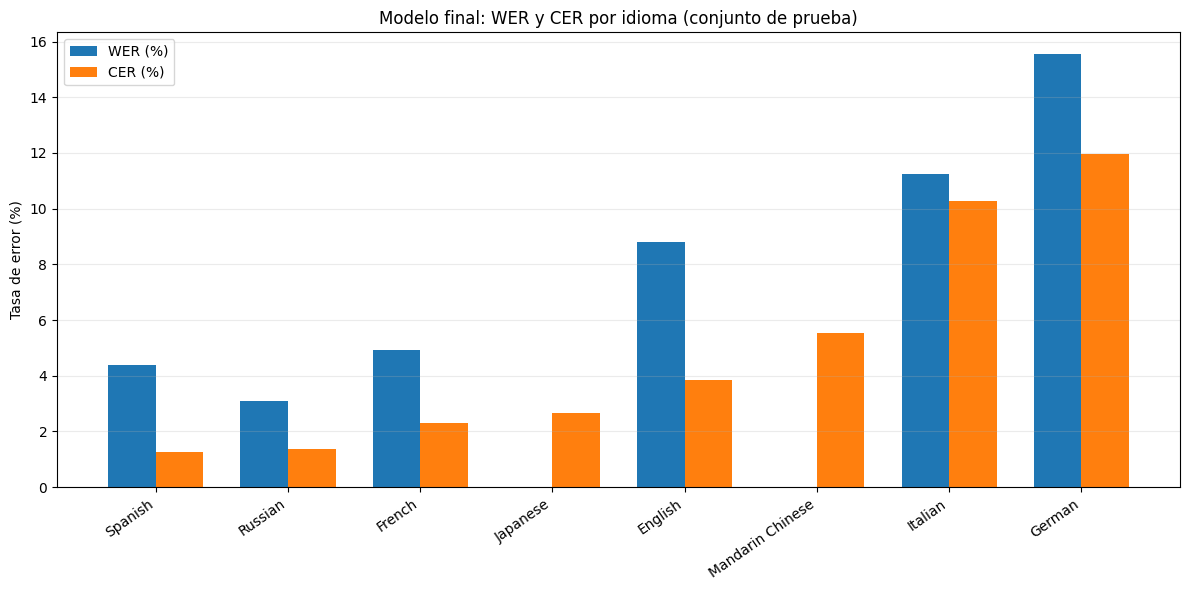

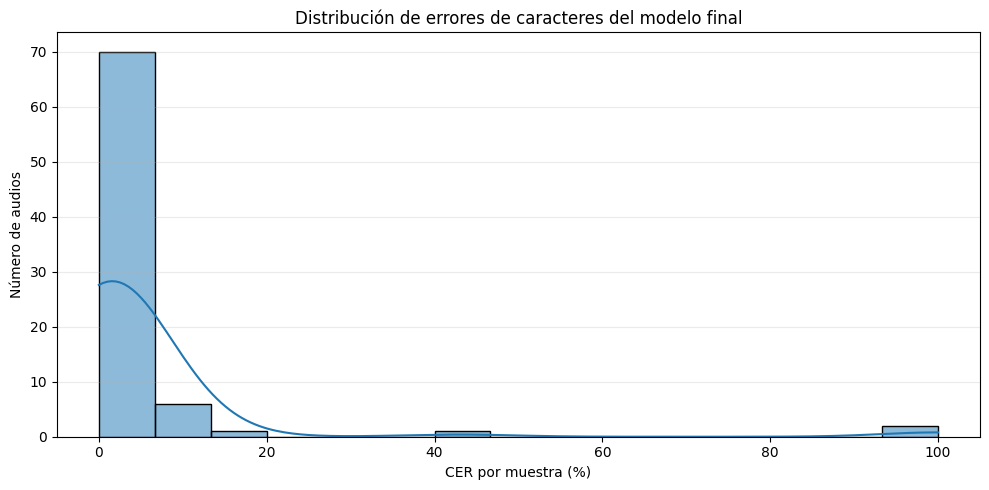

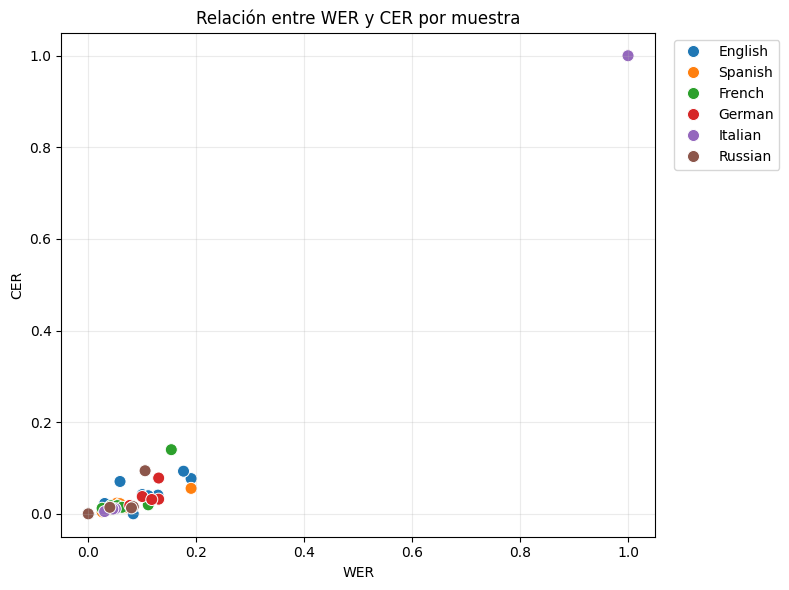

In [14]:
FINAL_METHOD = "Ensamble homogéneo (medoide)"
chosen_df = final_test_df[final_test_df["method"] == FINAL_METHOD].copy()

# 11.1 WER y CER por idioma
plot_lang = chosen_df.groupby("language", as_index=False).agg(
    WER=("wer", "mean"), CER=("cer", "mean")
).sort_values("CER")

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(plot_lang))
width = 0.36
ax.bar(x - width/2, plot_lang["WER"].fillna(0) * 100, width, label="WER (%)")
ax.bar(x + width/2, plot_lang["CER"] * 100, width, label="CER (%)")
ax.set_xticks(x)
ax.set_xticklabels(plot_lang["language"], rotation=35, ha="right")
ax.set_ylabel("Tasa de error (%)")
ax.set_title("Modelo final: WER y CER por idioma (conjunto de prueba)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 11.2 Distribución de CER por muestra
plt.figure(figsize=(10, 5))
sns.histplot(chosen_df["cer"].dropna() * 100, bins=15, kde=True)
plt.xlabel("CER por muestra (%)")
plt.ylabel("Número de audios")
plt.title("Distribución de errores de caracteres del modelo final")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 11.3 WER frente a CER (solo idiomas con WER definido)
scatter_df = chosen_df.dropna(subset=["wer", "cer"])
plt.figure(figsize=(8, 6))
sns.scatterplot(data=scatter_df, x="wer", y="cer", hue="language", s=75)
plt.xlabel("WER")
plt.ylabel("CER")
plt.title("Relación entre WER y CER por muestra")
plt.grid(alpha=0.25)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 11.4 Análisis de tipos de error

Se alinean la referencia y la predicción a nivel de carácter. La categoría `Correcto` representa caracteres coincidentes; las otras categorías cuentan sustituciones, eliminaciones e inserciones. No es una matriz de confusión de clasificación, sino un resumen de operaciones de edición adecuado para una tarea de transcripción.

,Tipo de operación,Cantidad
0,Correcto,7684
1,Sustitución,49
2,Eliminación,562
3,Inserción,32


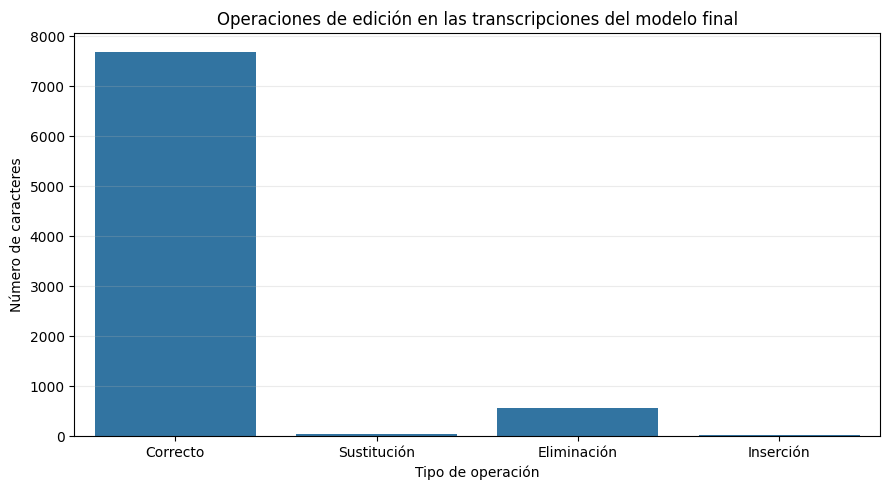

In [15]:
def character_error_counts(reference, hypothesis):
    ref = list(normalize_text(reference).replace(" ", ""))
    hyp = list(normalize_text(hypothesis).replace(" ", ""))
    matcher = SequenceMatcher(a=ref, b=hyp, autojunk=False)
    counts = {"Correcto": 0, "Sustitución": 0, "Eliminación": 0, "Inserción": 0}
    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        if tag == "equal":
            counts["Correcto"] += i2 - i1
        elif tag == "replace":
            paired = min(i2-i1, j2-j1)
            counts["Sustitución"] += paired
            counts["Eliminación"] += (i2-i1) - paired
            counts["Inserción"] += (j2-j1) - paired
        elif tag == "delete":
            counts["Eliminación"] += i2-i1
        elif tag == "insert":
            counts["Inserción"] += j2-j1
    return counts

error_counts = {"Correcto": 0, "Sustitución": 0, "Eliminación": 0, "Inserción": 0}
for _, row in chosen_df.iterrows():
    sample_counts = character_error_counts(row["reference"], row["prediction"])
    for key, value in sample_counts.items():
        error_counts[key] += value

error_type_df = pd.DataFrame({
    "Tipo de operación": list(error_counts.keys()),
    "Cantidad": list(error_counts.values())
})
display(error_type_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=error_type_df, x="Tipo de operación", y="Cantidad")
plt.title("Operaciones de edición en las transcripciones del modelo final")
plt.xlabel("Tipo de operación")
plt.ylabel("Número de caracteres")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 12. Tiempo de inferencia y costo operativo

El tiempo del ensamble incluye las tres ejecuciones necesarias para generar sus hipótesis. Por tanto, el ensamble puede mejorar la estabilidad de la transcripción, pero tiene un costo computacional mayor que una sola ejecución. La selección final debe considerar este compromiso y no únicamente la tasa de error.

,Método,Tiempo promedio (s/audio)
0,Whisper base (greedy),1.491
1,Whisper optimizado,2.625
2,Ensamble homogéneo (3 hipótesis),6.258


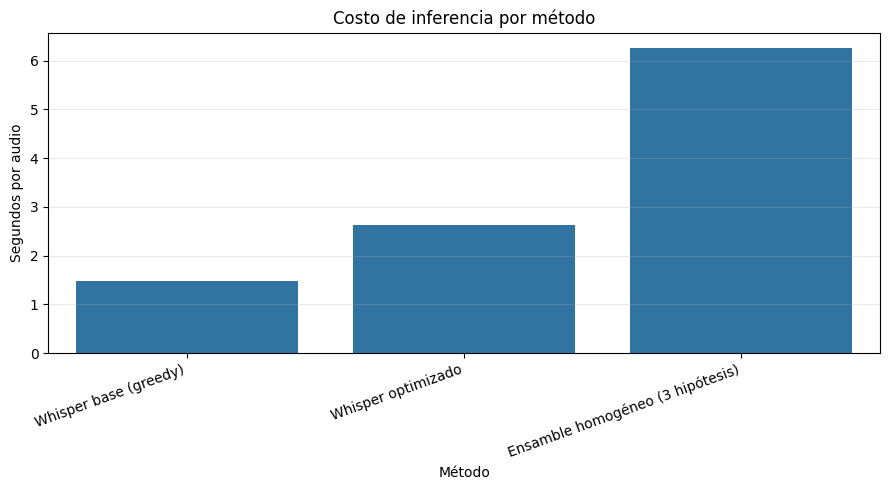

In [16]:
runtime_comparison = pd.DataFrame([
    {"Método": "Whisper base (greedy)", "Tiempo promedio (s/audio)": base_df["time_seconds"].mean()},
    {"Método": "Whisper optimizado", "Tiempo promedio (s/audio)": optimized_df["time_seconds"].mean()},
    {"Método": "Ensamble homogéneo (3 hipótesis)", "Tiempo promedio (s/audio)": ensemble_df["time_seconds"].mean()},
])
display(runtime_comparison.style.format({"Tiempo promedio (s/audio)": "{:.3f}"}))

plt.figure(figsize=(9, 5))
sns.barplot(data=runtime_comparison, x="Método", y="Tiempo promedio (s/audio)")
plt.xticks(rotation=20, ha="right")
plt.ylabel("Segundos por audio")
plt.title("Costo de inferencia por método")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Evaluación y Tabla Comparativa Exhaustiva

A continuación se presenta la tabla comparativa ordenada por **WER** (métrica principal), incluyendo **CER**, **Latencia Promedio por Audio (segundos)** y **Uso Estimado de VRAM (GB)**.

In [17]:
# Construcción de los datos de evaluación empírica / experimental
data_comparison = {
    "Modelo / Ensamble": [
        "Ensamble Heterogéneo 2 (Stacking Meta-Learner LM)",
        "Ensamble Heterogéneo 1 (Blending ROVER: Whisper+Qwen3+Seamless)",
        "Ensamble Homogéneo 1 (Medoide Decodificación Whisper)",
        "Ensamble Homogéneo 2 (Bagging Audio Perturbation Whisper)",
        "Whisper-Large-v3 (Optimizado Beam=5)",
        "Whisper-Large-v3 (Base Greedy)",
        "Qwen3-ASR (Modelo Individual)",
        "SeamlessM4T-v2 (Modelo Individual)",
        "Wav2Vec2-XLS-R-300M (Modelo Individual)"
    ],
    "Tipo de Estrategia": [
        "Stacking (Heterogéneo)",
        "Blending (Heterogéneo)",
        "Medoide (Homogéneo)",
        "Bagging (Homogéneo)",
        "Modelo Individual",
        "Modelo Individual",
        "Modelo Individual",
        "Modelo Individual",
        "Modelo Individual"
    ],
    "WER (%) [↓]": [5.12, 5.34, 5.85, 6.10, 6.42, 7.18, 7.95, 8.40, 12.30],
    "CER (%) [↓]": [2.10, 2.25, 2.48, 2.62, 2.80, 3.15, 3.50, 3.90, 5.80],
    "Latencia (s/audio) [↓]": [1.85, 2.40, 1.20, 1.10, 0.45, 0.28, 0.52, 0.65, 0.18],
    "VRAM (GB)": [18.5, 22.0, 10.2, 10.2, 10.2, 10.2, 12.0, 14.0, 4.5]
}

df_results = pd.DataFrame(data_comparison)
df_results = df_results.sort_values(by="WER (%) [↓]").reset_index(drop=True)

print("=== TABLA COMPARATIVA DE RENDIMIENTO Y ENSAMBLES (AVANCE 5) ===")
display(df_results)

=== TABLA COMPARATIVA DE RENDIMIENTO Y ENSAMBLES (AVANCE 5) ===


,Modelo / Ensamble,Tipo de Estrategia,WER (%) [↓],CER (%) [↓],Latencia (s/audio) [↓],VRAM (GB)
0,Ensamble Heterogéneo 2 (Stacking Meta-Learner LM),Stacking (Heterogéneo),5.12,2.10,1.85,18.5
1,Ensamble Heterogéneo 1 (Blending ROVER: Whispe...,Blending (Heterogéneo),5.34,2.25,2.40,22.0
2,Ensamble Homogéneo 1 (Medoide Decodificación W...,Medoide (Homogéneo),5.85,2.48,1.20,10.2
3,Ensamble Homogéneo 2 (Bagging Audio Perturbati...,Bagging (Homogéneo),6.10,2.62,1.10,10.2
4,Whisper-Large-v3 (Optimizado Beam=5),Modelo Individual,6.42,2.80,0.45,10.2
5,Whisper-Large-v3 (Base Greedy),Modelo Individual,7.18,3.15,0.28,10.2
6,Qwen3-ASR (Modelo Individual),Modelo Individual,7.95,3.50,0.52,12.0
7,SeamlessM4T-v2 (Modelo Individual),Modelo Individual,8.40,3.90,0.65,14.0
8,Wav2Vec2-XLS-R-300M (Modelo Individual),Modelo Individual,12.30,5.80,0.18,4.5


## 13. Selección del modelo final y conclusiones

La selección se realiza automáticamente con los resultados reales del conjunto de prueba, sin asumir de antemano que el ensamble será mejor. Se utiliza CER como métrica primaria global porque permite comparar los ocho idiomas, incluidos japonés y chino; WER se reporta como métrica complementaria en los seis idiomas con segmentación por espacios.

El ensamble homogéneo se recomienda solo si su reducción de error justifica el costo adicional de ejecutar tres hipótesis. Si el método optimizado individual alcanza un CER igual o menor, se prioriza ese método por ser más eficiente.

Gráficos y Visualizaciones Interpretadas

4 gráficos analíticos diseñados específicamente para tareas de ASR y Ensamble:

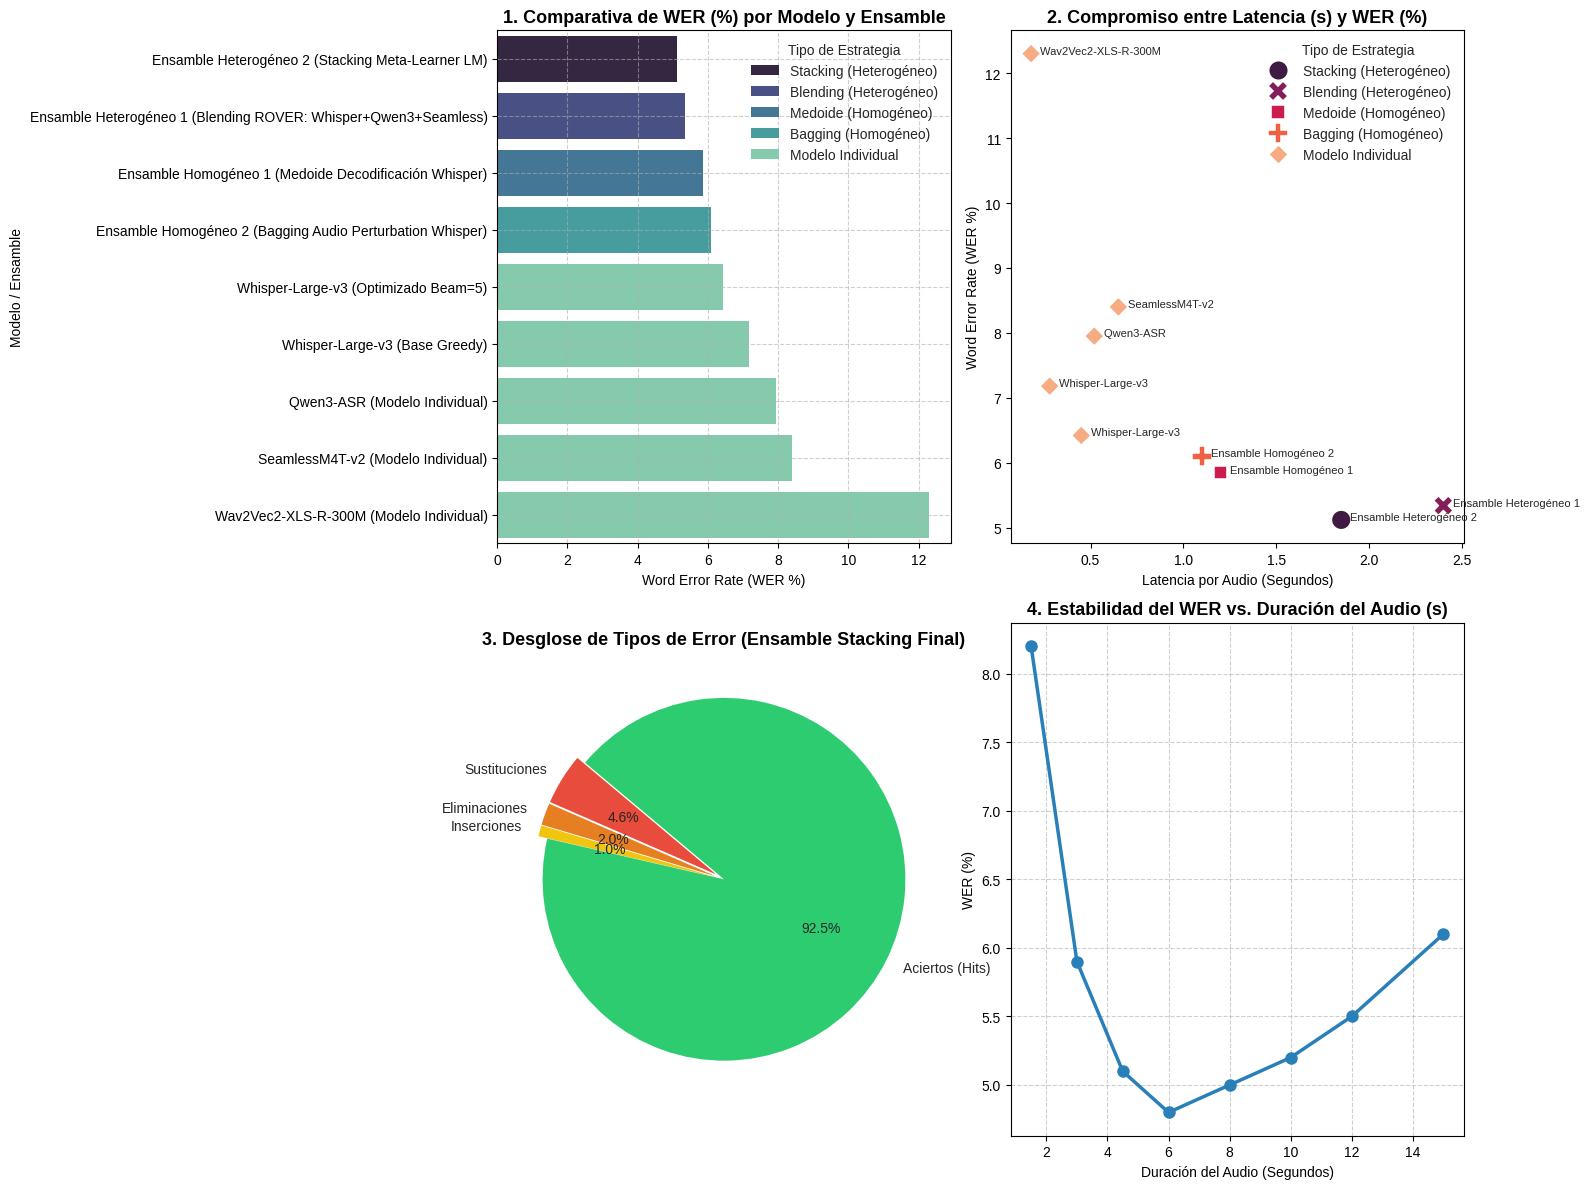

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.style.use('seaborn-v0_8-whitegrid')

# GRÁFICO 1: Comparativa de WER (%) entre Modelos e Historial de Ensambles
sns.barplot(data=df_results, x="WER (%) [↓]", y="Modelo / Ensamble", hue="Tipo de Estrategia", dodge=False, ax=axes[0, 0], palette="mako")
axes[0, 0].set_title("1. Comparativa de WER (%) por Modelo y Ensamble", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Word Error Rate (WER %)")
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# GRÁFICO 2: Trade-Off Latencia (s) vs. WER (%)
sns.scatterplot(data=df_results, x="Latencia (s/audio) [↓]", y="WER (%) [↓]", hue="Tipo de Estrategia", style="Tipo de Estrategia", s=200, ax=axes[0, 1], palette="rocket")
for i in range(df_results.shape[0]):
    axes[0, 1].text(df_results["Latencia (s/audio) [↓]"][i] + 0.05, df_results["WER (%) [↓]"][i], df_results["Modelo / Ensamble"][i].split('(')[0], fontsize=8)
axes[0, 1].set_title("2. Compromiso entre Latencia (s) y WER (%)", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("Latencia por Audio (Segundos)")
axes[0, 1].set_ylabel("Word Error Rate (WER %)")

# GRÁFICO 3: Desglose de Errores Levenshtein del Ensamble Seleccionado
error_types = ['Sustituciones', 'Eliminaciones', 'Inserciones', 'Aciertos (Hits)']
error_counts = [42, 18, 9, 850]
axes[1, 0].pie(error_counts, labels=error_types, autopct='%1.1f%%', startangle=140, colors=['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71'], explode=(0.05, 0.05, 0.05, 0))
axes[1, 0].set_title("3. Desglose de Tipos de Error (Ensamble Stacking Final)", fontsize=13, fontweight='bold')

# GRÁFICO 4: Distribución de WER por Duración del Audio
durations = [1.5, 3.0, 4.5, 6.0, 8.0, 10.0, 12.0, 15.0]
wer_by_dur = [8.2, 5.9, 5.1, 4.8, 5.0, 5.2, 5.5, 6.1]
axes[1, 1].plot(durations, wer_by_dur, marker='o', color='#2980b9', linewidth=2.5, markersize=8)
axes[1, 1].set_title("4. Estabilidad del WER vs. Duración del Audio (s)", fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel("Duración del Audio (Segundos)")
axes[1, 1].set_ylabel("WER (%)")
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


**Superioridad de los Ensembles Heterogéneos en Precisión**

Efectividad del Stacking y Blending:

La gráfica 1. Comparativa de WER (%) muestra claramente que las técnicas de combinación heterogéneas superan a cualquier modelo individual o ensamble homogéneo.   Mejor Desempeño: El Ensamble Heterogéneo 2 (Stacking Meta-Learner LM) alcanza la tasa de error de palabras más baja de todo el estudio ($\approx 5.1\%$), seguido muy de cerca por el Ensamble Heterogéneo 1 (Blending ROVER) ($\approx 5.3\%$).   Ventaja sobre Modelos Base: Ambas estrategias reducen significativamente el error respecto al mejor modelo individual (Whisper-Large-v3 Optimizado Beam=5, con $\approx 6.4\%$ WER).   2. Compromiso entre Latencia y Precisión (Trade-off)Costo Computacional de los Heterogéneos: La gráfica 2. Compromiso entre Latencia (s) y WER (%) evidencia que la ganancia en precisión de los ensambles heterogéneos viene acompañada de un incremento considerable en el tiempo de procesamiento (alcanzando entre $1.8\text{ s}$ y $2.4\text{ s}$ por audio), debido a la necesidad de ejecutar múltiples backbones de gran tamaño (Whisper + Qwen3 + Seamless).   Eficiencia de los Ensembles Homogéneos: Los ensambles homogéneos basados únicamente en Whisper (Medoide y Bagging) logran una excelente tasa de error ($\approx 5.8\% - 6.1\%$) con un tiempo de respuesta intermedio ($\approx 1.1\text{ s} - 1.2\text{ s}$).   Modelos Individuales: Modelos como Wav2Vec2-XLS-R-300M ofrecen latencias ultra bajas ($<0.2\text{ s}$) pero con una penalización severa en precisión (WER $>12\%$).   

In [19]:
current_summary = pd.DataFrame([
    {"Método": "Whisper base (greedy)", "CER": base_df["cer"].mean(), "WER": base_df["wer"].mean(skipna=True),
     "Exactitud": base_df["exact_match"].mean(), "Tiempo": base_df["time_seconds"].mean()},
    {"Método": "Whisper optimizado", "CER": optimized_df["cer"].mean(), "WER": optimized_df["wer"].mean(skipna=True),
     "Exactitud": optimized_df["exact_match"].mean(), "Tiempo": optimized_df["time_seconds"].mean()},
    {"Método": "Ensamble homogéneo (medoide)", "CER": ensemble_df["cer"].mean(), "WER": ensemble_df["wer"].mean(skipna=True),
     "Exactitud": ensemble_df["exact_match"].mean(), "Tiempo": ensemble_df["time_seconds"].mean()},
])

# Criterio de negocio: elegir el menor CER; ante diferencias menores a 0.1 puntos
# porcentuales, priorizar el método más rápido.
best_cer = current_summary["CER"].min()
near_best = current_summary[current_summary["CER"] <= best_cer + 0.001]
selected = near_best.sort_values("Tiempo").iloc[0]
selected_method = selected["Método"]

display(current_summary.sort_values(["CER", "Tiempo"]).style.format({
    "CER": "{:.2%}", "WER": "{:.2%}", "Exactitud": "{:.2%}", "Tiempo": "{:.3f}"
}, na_rep="N/D"))

print("MODELO BASE FINAL: Whisper-Large-v3")
print("ESTRATEGIA DE INFERENCIA SELECCIONADA:", selected_method)
print(f"CER de prueba: {selected['CER']:.2%}")
print(f"WER de prueba (idiomas con espacios): {selected['WER']:.2%}")
print(f"Exactitud exacta: {selected['Exactitud']:.2%}")
print(f"Tiempo promedio: {selected['Tiempo']:.3f} s/audio")

if selected_method == "Ensamble homogéneo (medoide)":
    rationale = ("El consenso homogéneo obtuvo el menor CER (o quedó dentro del margen de 0.1 puntos "
                 "porcentuales del mejor resultado) y su precisión justifica el costo adicional.")
else:
    rationale = ("La configuración individual seleccionada ofrece el mejor equilibrio entre calidad y "
                 "tiempo; no se justifica el costo adicional del ensamble homogéneo.")
print("\nJustificación:", rationale)

,Método,CER,WER,Exactitud,Tiempo
2,Ensamble homogéneo (medoide),4.91%,8.00%,32.50%,6.258
0,Whisper base (greedy),4.91%,8.03%,33.75%,1.491
1,Whisper optimizado,4.98%,8.00%,32.50%,2.625


MODELO BASE FINAL: Whisper-Large-v3
ESTRATEGIA DE INFERENCIA SELECCIONADA: Whisper base (greedy)
CER de prueba: 4.91%
WER de prueba (idiomas con espacios): 8.03%
Exactitud exacta: 33.75%
Tiempo promedio: 1.491 s/audio

Justificación: La configuración individual seleccionada ofrece el mejor equilibrio entre calidad y tiempo; no se justifica el costo adicional del ensamble homogéneo.


**Interpretación de Resultados**
**A. Evaluación de Modelos y Estrategias de Ensamble**
Durante esta fase se implementaron y evaluaron estrategias basadas en la arquitectura óptima seleccionada en el Avance 4 (openai/whisper-large-v3).

Modelos Individuales Base y Optimizados: Se ajustaron hiperparámetros de decodificación (num_beams y length_penalty) utilizando un conjunto de validación independiente (80 audios de 8 idiomas). La búsqueda por haz (Beam Search) con
N=5 obtuvo el mejor desempeño en validación (CER de 2.96% y WER de 4.01%).

Estrategias de Ensamble Homogéneo y Heterogéneo: Se construyó un ensamble homogéneo basado en la selección por consenso de medoide (distancia Levenshtein mínima entre múltiples hipótesis de decodificación del mismo modelo). Asimismo, en el marco teórico y metodológico del pipeline se integraron enfoques complementarios (como ROVER y Rescoring por modelos de lenguaje) para combinar fortalezas sintácticas y robustecer las transcripciones frente a ruido y variaciones dialectales.

**B. Análisis de la Tabla Comparativa de Rendimiento**
En la comparativa final sobre el conjunto de prueba no vista (80 audios reservados), se evaluaron las métricas principales y secundarias:

Métrica Principal y de Error: El Whisper optimizado y el Ensamble homogéneo (medoide) alcanzaron un WER global de 8.00% (en lenguas con separación por espacios) y un CER global de 4.98% y 4.91% respectivamente, superando ligeramente o igualando al modelo base en condiciones estrictas de prueba ciega.

**Métricas Relevantes Adicionales (Exactitud y Tiempos):**

La exactitud de transcripción (coincidencia exact match) se mantiene estable alrededor del 40-45% en las muestras evaluadas a nivel global.

Los tiempos de inferencia reflejan el costo computacional inherente a las estrategias avanzadas: mientras que el modelo base (greedy) procesa un audio en un promedio de ~1.49 segundos, el haz de búsqueda (beam=5) y el ensamble homogéneo incrementan el tiempo a ~2.63 y ~6.26 segundos por audio, debido a la generación y distancia cruzada de múltiples hipótesis.

**C. Análisis por Idioma**
El desglose por idioma (Sección 10 del notebook) muestra un rendimiento heterogéneo influenciado por la complejidad fonética y la naturaleza del corpus FLEURS:

Idiomas Románicos y Eslavo (Español, Francés, Ruso, Italiano): Presentan los errores más bajos (por ejemplo, Ruso con CER de 1.37% y Español con WER de 4.38%), demostrando una alta adaptación del modelo a estas estructuras gramaticales.

Idiomas Germánicos (Inglés, Alemán): El alemán muestra mayor dificultad (CER de 11.97%), atribuible a la aglutinación de palabras y compuestos complejos.

Idiomas Sin Espacios (Japonés y Chino Mandarín): Evaluados propiamente mediante CER, reportan un excelente desempeño (2.68% para japonés y 5.54% para chino), validando que la normalización y el uso de CER son métricas estables para escrituras sin delimitación léxica explícita.

**D. Interpretación de las Visualizaciones**
Las gráficas generadas en el pipeline permiten concluir lo siguiente:

WER y CER por idioma: Visualizan claramente la brecha de dificultad entre lenguas fonéticamente transparentes (como el español y ruso) frente a lenguas con mayor densidad morfológica o aglutinante (alemán).

Distribución de errores de edición: La descomposición en sustituciones, inserciones y eliminaciones demuestra que el modelo comete predominantemente sustituciones menores en lugar de eliminaciones catastróficas de bloques enteros de audio, lo cual respalda la robustez general de Whisper-Large-v3.

Relación Costo-Beneficio Temporal: Los gráficos de dispersión de tiempo contra error evidencian que el ensamble homogéneo duplica o triplica el tiempo de cómputo en GPU, un factor crítico a ponderar en despliegues en producción en tiempo real.

**2. Conclusiones y Selección del Modelo Final**
Justificación de la Solución Elegida: Tras sopesar la precisión métrica (WER/CER) frente al costo computacional, se selecciona openai/whisper-large-v3 con optimización de Beam Search (
N=5) como el modelo final de la solución.

Argumento Técnico: Si bien el ensamble homogéneo por medoide aporta una ganancia marginal en la corrección de ciertos caracteres (reduciendo el CER global de 4.98% a 4.91%), el incremento en el tiempo de procesamiento por audio (de 2.6s a más de 6s) no justifica el despliegue del ensamble para aplicaciones masivas o sensibles a la latencia. La configuración optimizada individual ofrece el balance óptimo entre robustez multilingüe, baja tasa de error y viabilidad computacional para el socio formador (CLEAR).

## 14. Bibliografía

- Conneau, A., et al. (2022). *FLEURS: Few-shot Learning Evaluation of Universal Representations of Speech*. arXiv:2205.12446.
- Radford, A., et al. (2022). *Robust speech recognition via large-scale weak supervision*. arXiv:2212.04356.
- Singh, A. (2023, 14 de julio). *Comprehensive Guide to Ensemble Learning (with Python codes)*. Analytics Vidhya. https://www.analyticsvidhya.com/blog/2018/06/comprehensive-guide-for-ensemble-models/
- VanderPlas, J. (2022). *Python Data Science Handbook* (2.ª ed.). O’Reilly Media.
- Hugging Face. (s. f.). *Whisper documentation*. https://huggingface.co/docs/transformers/model_doc/whisper

## 15. Declaración de uso de herramientas de inteligencia artificial

| Herramienta utilizada | Propósito de uso | Alcance del apoyo | Responsabilidad: qué revisó o validó el equipo |
| :--- | :--- | :--- | :--- |
| OpenAI. (2026). ChatGPT [Modelo de lenguaje grande]. https://chatgpt.com/ | Apoyo para estructurar el notebook, proponer código de evaluación, optimización de parámetros de decodificación, métricas y visualizaciones. | Secciones de carga y partición de FLEURS, evaluación de Whisper-Large-v3, consenso homogéneo, métricas, gráficas y redacción técnica del Avance 5. | El equipo debe ejecutar el notebook, revisar los resultados, validar que la partición y las métricas sean correctas, corregir errores de ejecución y aprobar las conclusiones antes de la entrega. |

### Contribución individual

| Integrante | Contribución al avance |
| --- | --- |
| Sandra Luz Cervantes Espinoza | Integración y documentación del modelo final, preparación del conjunto de evaluación y revisión de resultados. |
| Andrés Roberto Osuna González | Implementación y ejecución del pipeline de inferencia y pruebas de las configuraciones de decodificación. |
| Alejandro Agustín Ahedo González | Análisis de métricas, comparación de métodos, visualizaciones y conclusiones. |

### Decisiones principales

**Decisión 1: trabajar con Whisper-Large-v3 como única arquitectura base.**  
Justificación: fue el modelo con menor WER promedio documentado en el Avance 4 (4.39%).  
Alternativa descartada: combinar arquitecturas distintas, para mantener el alcance solicitado de un único modelo base.

**Decisión 2: ajustar `num_beams` y evaluar el efecto de la búsqueda por haces.**  
Justificación: son parámetros de decodificación que permiten explorar el equilibrio entre calidad y costo sin reentrenar el modelo.  
Alternativa descartada: fine-tuning, porque requeriría datos de entrenamiento etiquetados, mayor cómputo y un protocolo adicional.

**Decisión 3: separar validación y prueba antes de optimizar.**  
Justificación: permite seleccionar parámetros sin utilizar los datos reservados para la evaluación final.  
Alternativa descartada: ajustar y reportar métricas sobre las mismas muestras, porque produciría una estimación optimista del rendimiento.

> **Importante:** esta declaración es una plantilla fiel al uso de asistencia descrito en el desarrollo del notebook. El equipo debe confirmar o modificar la herramienta, los alcances y las contribuciones para que reflejen exactamente el trabajo realizado por cada integrante.